# Lab 08 -  Visualization techniques using 'matplotlib' and 'seaborn'and GroupBy Operations
## In this lab we are covering topics belonging to:
        - Matplotlib
        - Seaborn

In [3]:
# Adding necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

1. Write a program to draw line charts of the financial data of Alphabet Inc. between October 3, 2016 to October 7, 2016. (dataset: L07_01.csv)

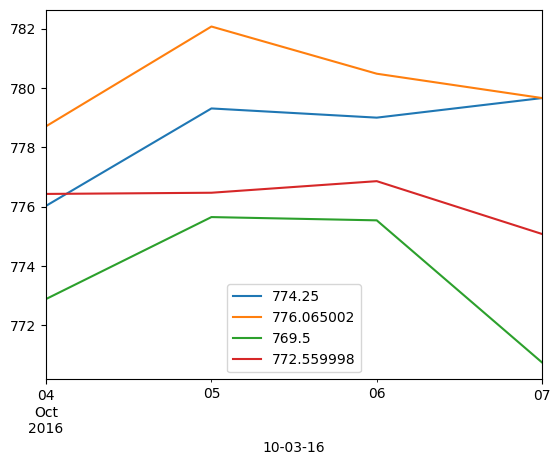

In [4]:
# your code:
df = pd.read_csv('../data/L07_01.csv', sep=',', parse_dates=True, index_col=0) #
df.plot()
plt.show()

2. Write a program to display a bar chart of the popularity of programming Languages.
Add: xlabel, ylabel, title, xticks, and a grid

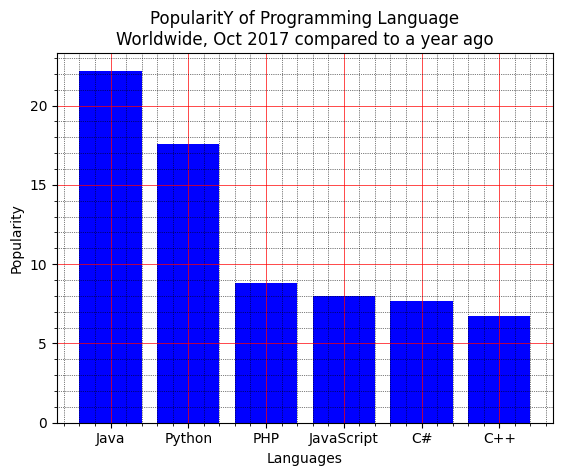

In [8]:
languages = ['Java', 'Python', 'PHP', 'JavaScript', 'C#', 'C++']
popularity = [22.2, 17.6, 8.8, 8, 7.7, 6.7]

# your code:

x_pos = [i for i, _ in enumerate(languages)]
plt.bar(x_pos, popularity, color='blue')
plt.xlabel("Languages")
plt.ylabel("Popularity")
plt.title("PopularitY of Programming Language\n" + "Worldwide, Oct 2017 compared to a year ago")
plt.xticks(x_pos, languages)
# Turn on the grid
plt.minorticks_on()
plt.grid(which='major', linestyle='-', linewidth='0.5', color='red')
# Customize the minor grid
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='black')
plt.show()

3. Write a program to create bar plot of scores by group and gender. Use multiple X values on the same chart for men and women.

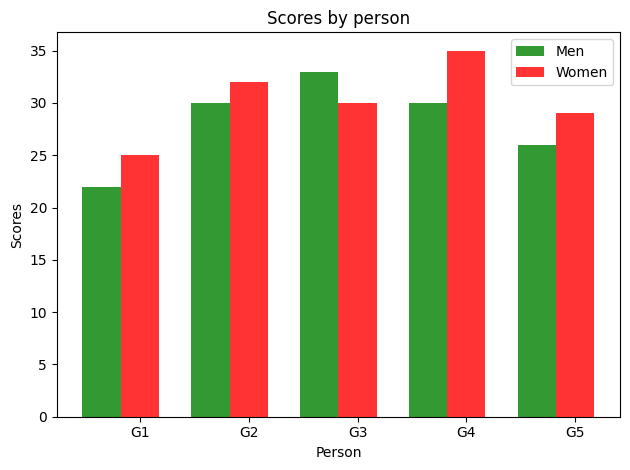

In [9]:
men_means = (22, 30, 33, 30, 26)
women_means = (25, 32, 30, 35, 29)

# your code:

n_groups = 5
fig, ax = plt.subplots()
index = np.arange(n_groups)
bar_width = 0.35
opacity = 0.8

rects1 = plt.bar(index, men_means, bar_width,
alpha=opacity,
color='g',
label='Men')

rects2 = plt.bar(index + bar_width, women_means, bar_width,
alpha=opacity,
color='r',
label='Women')

plt.xlabel('Person')
plt.ylabel('Scores')
plt.title('Scores by person')
plt.xticks(index + bar_width, ('G1', 'G2', 'G3', 'G4', 'G5'))
plt.legend()

plt.tight_layout()
plt.show()


4. Write a program to create a pie chart of gold medal achievements of five most successful countries in 2016 Summer Olympics. (dataset: L07_02.csv)

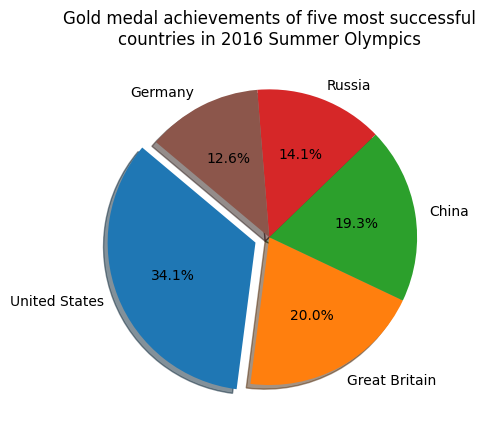

In [12]:
# your code:

df =  pd.read_csv('../data/L07_02.csv')
country_data = df["country"]
medal_data = df["gold_medal"]
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#8c564b"]
explode = (0.1, 0, 0, 0, 0)  
plt.pie(medal_data, labels=country_data, explode=explode, colors=colors,
autopct='%1.1f%%', shadow=True, startangle=140)
plt.title("Gold medal achievements of five most successful\n"+"countries in 2016 Summer Olympics")
plt.show()

5. Write a program to draw a scatter plot to find sea level rise in past 100 years. (dataset: L07_03.csv)

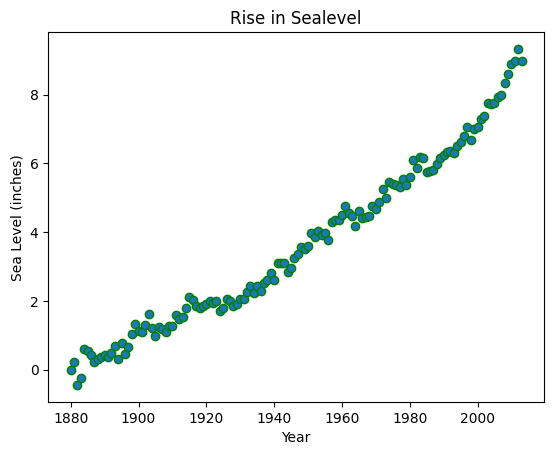

In [14]:
# your code:

data = pd.read_csv('../data/L07_03.csv')
year = data['Year']
sea_levels = data['CSIRO Adjusted Sea Level']
plt.scatter(year, sea_levels, edgecolors='g')
plt.xlabel('Year')
plt.ylabel('Sea Level (inches)')
plt.title('Rise in Sealevel')
plt.show()

# In the next questions, you work with use Seaborn library for creating charts.
Import (Pokemon.csv) dataset and create plots and charts using this dataset in the following exercises.

6. Create a scatter plot to compare the Attack and Defense stats for pokemons.
(Hint: sns.lmplot())

In [16]:
# read the dataset
df = pd.read_csv('../data/Pokemon.csv', index_col=0, encoding='latin')

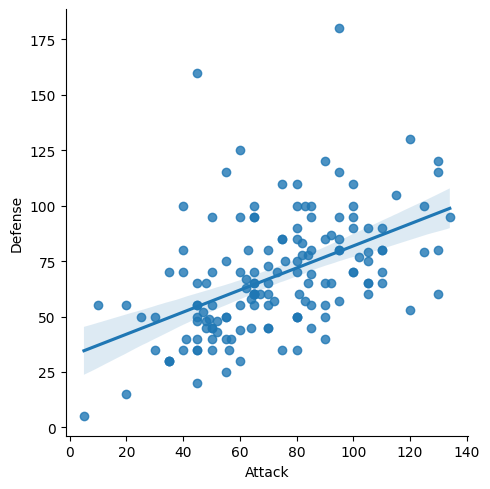

In [ ]:
# your code:

sns.lmplot(x='Attack', y='Defense', data=df)

7. From previous chart you may find a trend in the scatterplot but we may not want it.

a.  Remove itusing a keyword argument in the scatterplot function, Visit Seaborn documentation!

b.  Color points based on the "Stage" of the pokemons.

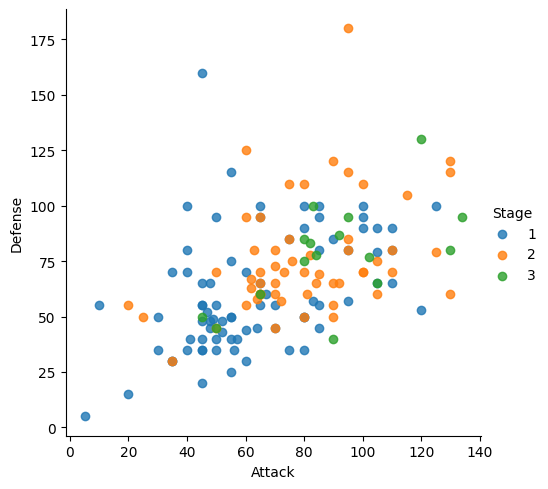

In [17]:
# your code:

sns.lmplot(x='Attack', y='Defense', data=df,
           fit_reg=False, # No regression line
           hue='Stage')   # Color by evolution stage

8. Use the previous dataframe for making boxplots. They play a vital role in stock market and other trading analysis.

a. Create a boxplot for pokemons combat stats. (Hint: pass the dataframe to appropriate function.)

b. Does it appear to be a meaningful plot? May be some columns can be removed. (Drop those columns in the dataframe and replot it.)

<Axes: >

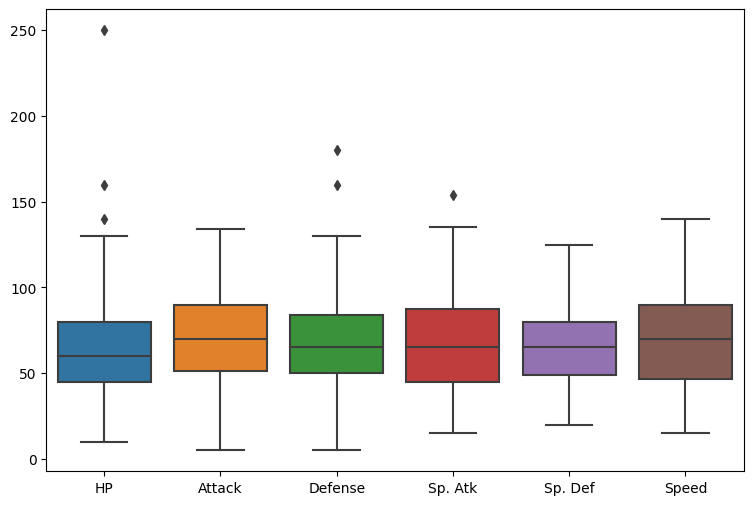

In [18]:
# your code:

stats_df = df.drop(['Total', 'Stage', 'Legendary'], axis=1)
# boxplot using stats_df
plt.figure(figsize=(9,6)) # Set plot dimensions
sns.boxplot(data=stats_df)

9. We want to visualize the distribution of Attack by Pokémon’s primary type (Type 1). There is a list containing color palettes for making our chart better looking!

  a. use Swarm plot function and the color palettes to see the final result.
  b. use violin plot for the same purpose.

In [19]:

pkmn_type_colors = ['#78C850',  # Grass
                    '#F08030',  # Fire
                    '#6890F0',  # Water
                    '#A8B820',  # Bug
                    '#A8A878',  # Normal
                    '#A040A0',  # Poison
                    '#F8D030',  # Electric
                    '#E0C068',  # Ground
                    '#EE99AC',  # Fairy
                    '#C03028',  # Fighting
                    '#F85888',  # Psychic
                    '#B8A038',  # Rock
                    '#705898',  # Ghost
                    '#98D8D8',  # Ice
                    '#7038F8',  # Dragon
                   ]

<Axes: xlabel='Type 1', ylabel='Attack'>

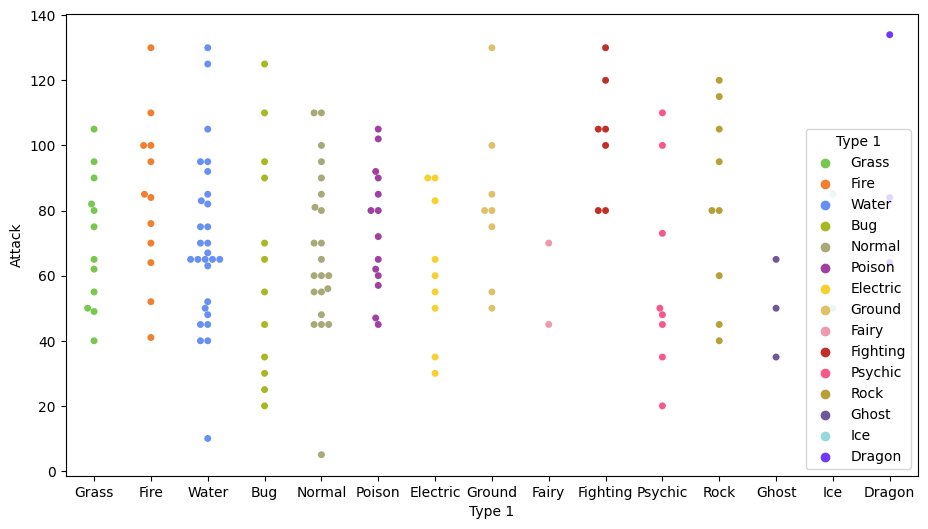

In [23]:
# your code:

plt.figure(figsize=(11,6)) # Set plot dimensions
sns.swarmplot(x='Type 1', y='Attack', data=df, 
              palette=pkmn_type_colors, hue='Type 1')

<Axes: xlabel='Type 1', ylabel='Attack'>

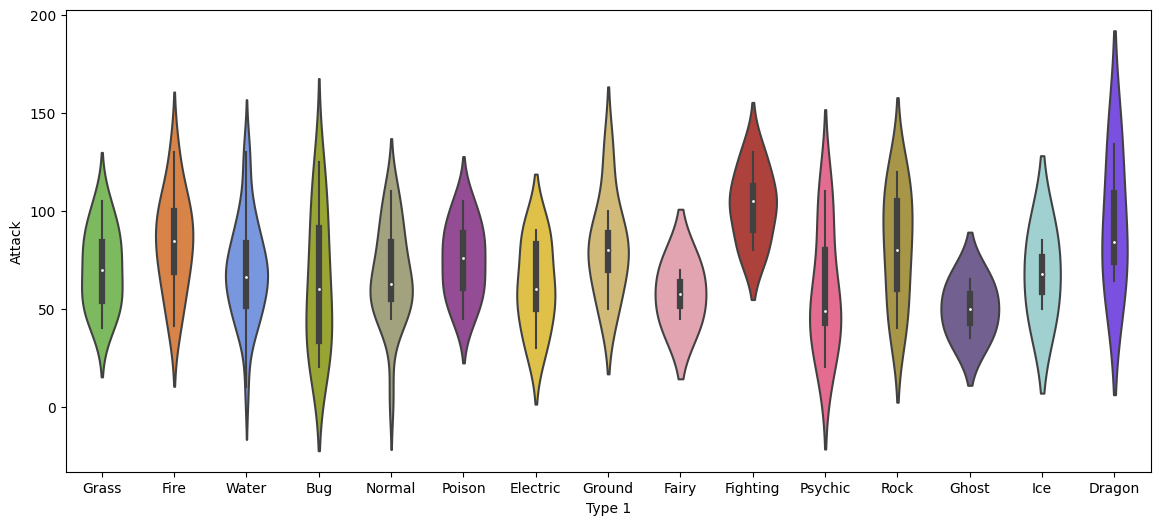

In [24]:

plt.figure(figsize=(14,6)) 
sns.violinplot(x='Type 1',y='Attack',palette=pkmn_type_colors, data=df)

10. Make a joint plot to compre the speed and attack of pokemons for visualing suitable combination.


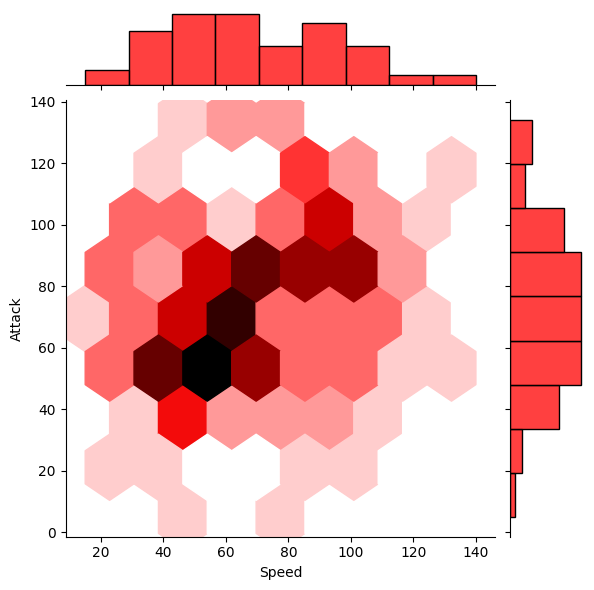

In [25]:
sns.jointplot(x='Speed', y='Attack', data=df, color = "Red", kind ='hex', height= 6.0)

# GroupBy Operations:
11. Using the dataset, Pokemon.csv, group the Pokémon by their Attack values and calculate the average Speed for each attack group. Write code to perform this grouping and display the result.

In [ ]:
df = pd.read_csv('../data/Pokemon.csv', index_col=0, encoding='latin')


average_Speed = df.groupby('Attack')['Speed'].mean()
print(average_Speed)


# Creating a Pivot Table
12. Using the dataset, Pokemon.csv, create a pivot table that groups data by the Type 1 column and summarizes the total HP, Attack, and Defense for each type. Then, identify the top three types based on the sum of these statistics. Write the code to achieve this and explain what the top three types represent in terms of overall strength.

In [ ]:
pivot_table = df.pivot_table(index='Type 1', values=['HP', 'Attack', 'Defense'], aggfunc='sum')


top_countries = pivot_table.sum(axis=1).nlargest(3)
print(top_countries)